In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/diabetes_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (101766, 52)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,a1c_result_recorded,glucose_result_recorded,readmitted_30_days
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,...,No,No,No,No,No,No,NO,0,0,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,...,No,No,No,No,Ch,Yes,>30,0,0,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,...,No,No,No,No,No,Yes,NO,0,0,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,...,No,No,No,No,Ch,Yes,NO,0,0,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,...,No,No,No,No,Ch,Yes,NO,0,0,0


In [9]:
# Calculate 30-day readmission statistics
total_encounters = len(df)
readmitted = df["readmitted_30_days"].sum()

readmission_rate = (readmitted / total_encounters) * 100

print(f"Total hospital encounters: {total_encounters:,}")
print(f"30-day readmissions: {readmitted:,}")
print(f"30-day readmission rate: {readmission_rate:.2f}%")

Total hospital encounters: 101,766
30-day readmissions: 11,357
30-day readmission rate: 11.16%


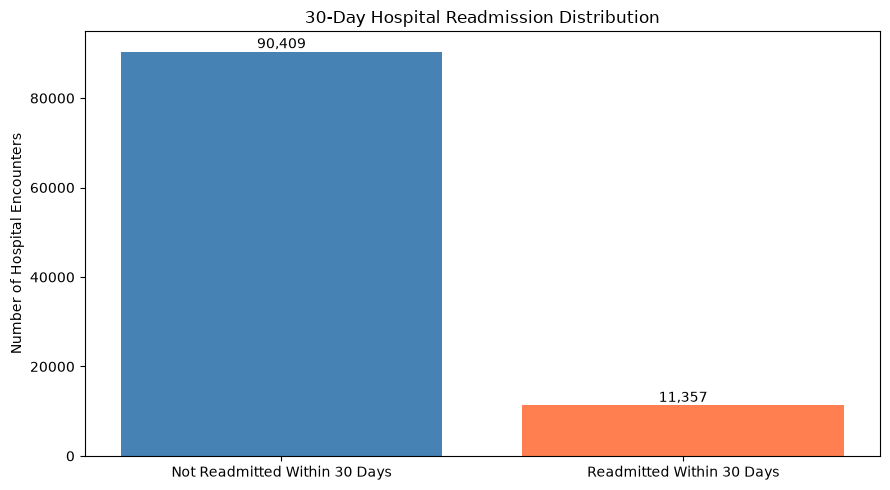

In [15]:
import matplotlib.pyplot as plt

counts = df["readmitted_30_days"].value_counts().sort_index()

labels = [
    "Not Readmitted Within 30 Days",
    "Readmitted Within 30 Days"
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    counts.values,
    color=["steelblue", "coral"]
)

plt.title("30-Day Hospital Readmission Distribution")
plt.ylabel("Number of Hospital Encounters")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Finding 1: Overall 30-Day Readmission Rate

Of the 101,766 hospital encounters analyzed, 11,357 (11.16%) were followed by readmission within 30 days. The remaining 88.84% were not readmitted within that period. This establishes a baseline for examining differences in readmission rates across patient groups and hospital utilization characteristics.

In [11]:
# Calculate readmission rates by age group
age_analysis = (
    df.groupby("age")["readmitted_30_days"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

age_analysis.columns = [
    "Age Group",
    "Total Encounters",
    "30-Day Readmissions",
    "Readmission Rate"
]

age_analysis["Readmission Rate"] = (
    age_analysis["Readmission Rate"] * 100
).round(2)

display(age_analysis)

,Age Group,Total Encounters,30-Day Readmissions,Readmission Rate
0,[0-10),161,3,1.86
1,[10-20),691,40,5.79
2,[20-30),1657,236,14.24
3,[30-40),3775,424,11.23
4,[40-50),9685,1027,10.60
5,[50-60),17256,1668,9.67
6,[60-70),22483,2502,11.13
7,[70-80),26068,3069,11.77
8,[80-90),17197,2078,12.08
9,[90-100),2793,310,11.10


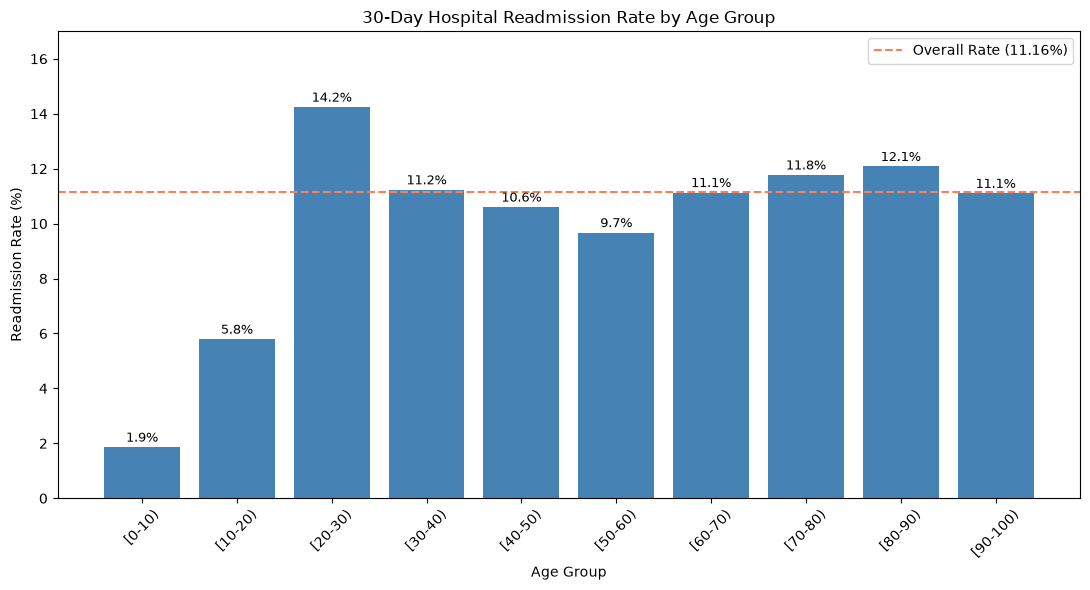

In [12]:
# Visualize 30-day readmission rates by age group
plt.figure(figsize=(11, 6))

bars = plt.bar(
    age_analysis["Age Group"],
    age_analysis["Readmission Rate"],
    color="steelblue"
)

# Overall readmission rate for comparison
overall_rate = df["readmitted_30_days"].mean() * 100

plt.axhline(
    overall_rate,
    color="coral",
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.title("30-Day Hospital Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)
plt.legend()

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=9
    )

plt.ylim(0, 17)
plt.tight_layout()
plt.show()

### Finding 2: Readmission Patterns by Age Group

Readmission rates varied across age groups. Encounters involving patients aged 20–30 had the highest observed 30-day readmission rate at 14.24%, while those aged 80–90 had a rate of 12.08%.

Patients aged 70–80 accounted for the largest number of 30-day readmissions, with 3,069 encounters. These findings show differences across age groups, although additional analysis is needed to understand other factors associated with readmission.

In [13]:
# Group encounters by number of previous inpatient visits
inpatient_analysis = (
    df.groupby("number_inpatient")["readmitted_30_days"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

inpatient_analysis.columns = [
    "Previous Inpatient Visits",
    "Total Encounters",
    "30-Day Readmissions",
    "Readmission Rate"
]

inpatient_analysis["Readmission Rate"] = (
    inpatient_analysis["Readmission Rate"] * 100
).round(2)

display(inpatient_analysis)

,Previous Inpatient Visits,Total Encounters,30-Day Readmissions,Readmission Rate
0,0,67630,5706,8.44
1,1,19521,2523,12.92
2,2,7566,1319,17.43
3,3,3411,692,20.29
4,4,1622,383,23.61
5,5,812,255,31.40
6,6,480,166,34.58
7,7,268,95,35.45
8,8,151,67,44.37
9,9,111,47,42.34


In [14]:
# Group previous inpatient visits into categories
df["inpatient_visit_group"] = pd.cut(
    df["number_inpatient"],
    bins=[-1, 0, 1, 2, 4, float("inf")],
    labels=["0", "1", "2", "3–4", "5+"]
)

# Calculate readmission rates by visit group
inpatient_grouped = (
    df.groupby(
        "inpatient_visit_group",
        observed=True
    )["readmitted_30_days"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

inpatient_grouped.columns = [
    "Previous Visits",
    "Total Encounters",
    "30-Day Readmissions",
    "Readmission Rate"
]

inpatient_grouped["Readmission Rate"] = (
    inpatient_grouped["Readmission Rate"] * 100
).round(2)

display(inpatient_grouped)

,Previous Visits,Total Encounters,30-Day Readmissions,Readmission Rate
0,0,67630,5706,8.44
1,1,19521,2523,12.92
2,2,7566,1319,17.43
3,3–4,5033,1075,21.36
4,5+,2016,734,36.41


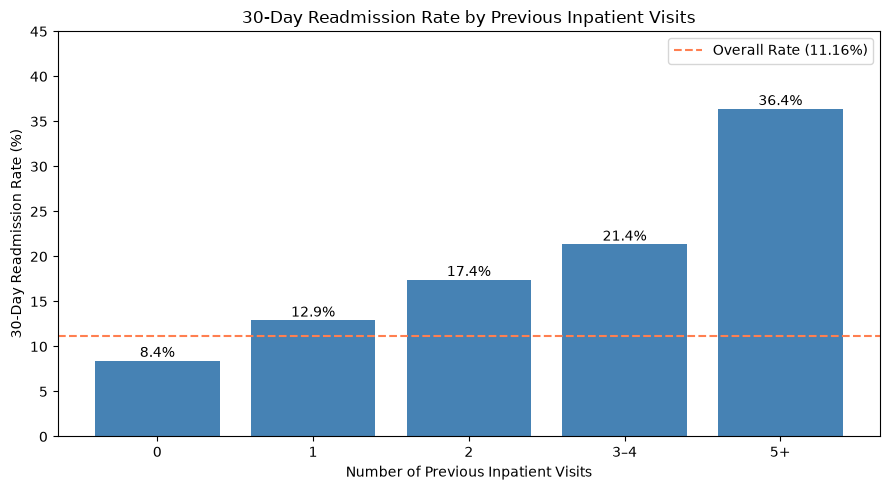

In [17]:
# Finding 3: Readmission rates by previous inpatient visits

plt.figure(figsize=(9, 5))

bars = plt.bar(
    inpatient_grouped["Previous Visits"].astype(str),
    inpatient_grouped["Readmission Rate"],
    color="steelblue"
)

# Add overall readmission rate
overall_rate = df["readmitted_30_days"].mean() * 100

plt.axhline(
    overall_rate,
    color="coral",
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

# Add titles and labels
plt.title("30-Day Readmission Rate by Previous Inpatient Visits")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("30-Day Readmission Rate (%)")

# Display percentages above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 45)
plt.legend()
plt.tight_layout()
plt.show()

### Finding 3: Previous Inpatient Visits and 30-Day Readmissions

The analysis revealed that 30-day readmission rates increased as the number of previous inpatient visits increased. Encounters involving patients with no previous inpatient visits had a readmission rate of 8.44%, compared with 36.41% for patients with five or more previous visits.

This suggests that previous hospital utilization may be an important indicator of readmission risk. Patients with frequent prior inpatient visits could be considered for additional discharge planning, follow-up care, or care coordination.

However, these findings demonstrate an association rather than causation, and further analysis is needed to account for other patient characteristics.

In [18]:
# Finding 4: Length of hospital stay and readmissions

stay_analysis = (
    df.groupby("time_in_hospital")["readmitted_30_days"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

stay_analysis.columns = [
    "Length of Stay (Days)",
    "Total Encounters",
    "30-Day Readmissions",
    "Readmission Rate"
]

stay_analysis["Readmission Rate"] = (
    stay_analysis["Readmission Rate"] * 100
).round(2)

display(stay_analysis)

,Length of Stay (Days),Total Encounters,30-Day Readmissions,Readmission Rate
0,1,14208,1162,8.18
1,2,17224,1712,9.94
2,3,17756,1894,10.67
3,4,13924,1644,11.81
4,5,9966,1199,12.03
5,6,7539,949,12.59
6,7,5859,752,12.83
7,8,4391,625,14.23
8,9,3002,412,13.72
9,10,2342,336,14.35


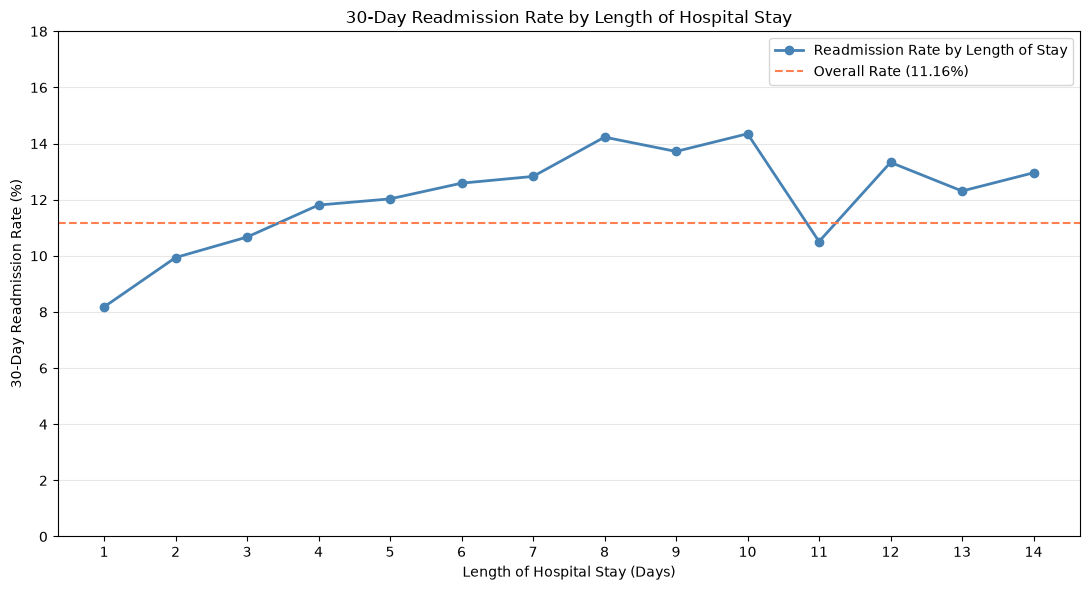

In [19]:
# Finding 4: Visualize readmission rates by length of stay

plt.figure(figsize=(11, 6))

plt.plot(
    stay_analysis["Length of Stay (Days)"],
    stay_analysis["Readmission Rate"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Readmission Rate by Length of Stay"
)

# Add overall readmission rate
overall_rate = df["readmitted_30_days"].mean() * 100

plt.axhline(
    overall_rate,
    color="coral",
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.title("30-Day Readmission Rate by Length of Hospital Stay")
plt.xlabel("Length of Hospital Stay (Days)")
plt.ylabel("30-Day Readmission Rate (%)")

plt.xticks(range(1, 15))
plt.ylim(0, 18)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Finding 4: Length of Hospital Stay and 30-Day Readmissions

The analysis showed that longer hospital stays were generally associated with higher observed 30-day readmission rates. Encounters involving one-day hospital stays had a readmission rate of 8.18%, compared with 14.35% for ten-day stays.

Although readmission rates generally increased between one and ten days, the relationship was not consistent across all lengths of stay. For example, the rate decreased to 10.51% for eleven-day stays.

These findings suggest that length of stay may be a useful factor when analyzing hospital readmissions. However, differences in patient health conditions, illness severity, and treatment requirements may also influence the observed relationship. Additional analysis is necessary before drawing conclusions about the impact of hospital stay duration on readmission outcomes.

In [20]:
# Finding 5: Number of medications and 30-day readmissions

# Group medication counts into ranges
df["medication_group"] = pd.cut(
    df["num_medications"],
    bins=[-1, 5, 10, 15, 20, float("inf")],
    labels=["0-5", "6-10", "11-15", "16-20", "21+"]
)

medication_analysis = (
    df.groupby("medication_group", observed=True)["readmitted_30_days"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

medication_analysis.columns = [
    "Number of Medications",
    "Total Encounters",
    "30-Day Readmissions",
    "Readmission Rate"
]

medication_analysis["Readmission Rate"] = (
    medication_analysis["Readmission Rate"] * 100
).round(2)

display(medication_analysis)

,Number of Medications,Total Encounters,30-Day Readmissions,Readmission Rate
0,0-5,5066,379,7.48
1,6-10,20795,1965,9.45
2,11-15,29384,3206,10.91
3,16-20,22641,2756,12.17
4,21+,23880,3051,12.78


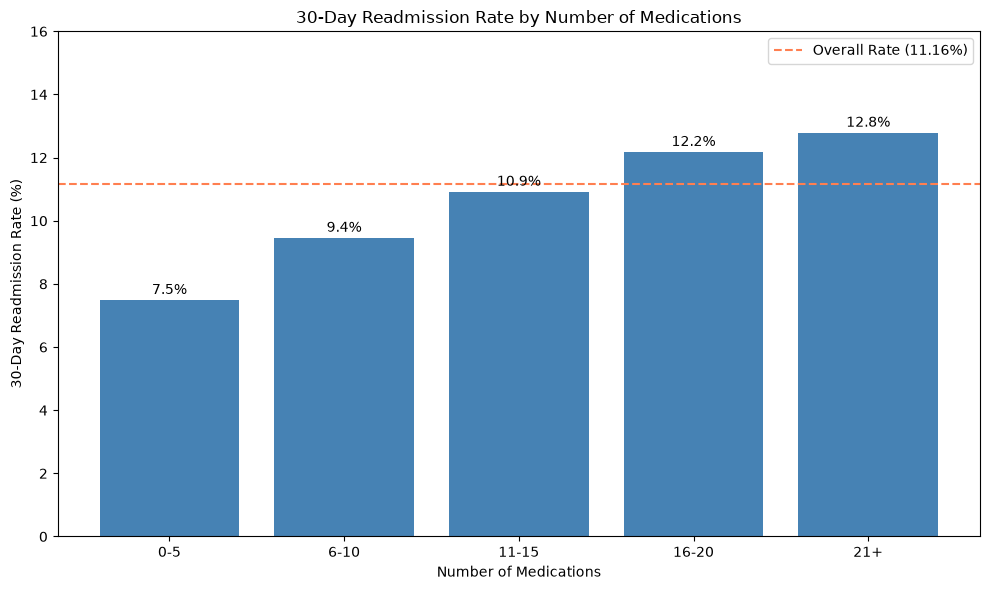

In [21]:
# Finding 5: Visualize readmission rates by medication count

plt.figure(figsize=(10, 6))

bars = plt.bar(
    medication_analysis["Number of Medications"],
    medication_analysis["Readmission Rate"],
    color="steelblue"
)

# Add overall readmission rate
overall_rate = df["readmitted_30_days"].mean() * 100

plt.axhline(
    overall_rate,
    color="coral",
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

# Add titles and labels
plt.title("30-Day Readmission Rate by Number of Medications")
plt.xlabel("Number of Medications")
plt.ylabel("30-Day Readmission Rate (%)")

# Display percentages above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 16)
plt.legend()
plt.tight_layout()
plt.show()

### Finding 5: Number of Medications and 30-Day Readmissions

The analysis revealed that 30-day readmission rates increased as the number of medications administered during hospitalization increased. Encounters involving 0–5 medications had a readmission rate of 7.48%, compared with 12.78% for encounters involving 21 or more medications.

These findings suggest that medication count may be associated with hospital readmission risk. A higher number of medications could reflect greater patient complexity, more intensive treatment, or underlying health conditions.

However, this relationship does not establish that receiving more medications causes readmissions. Additional analysis would be necessary to account for differences in patient health and treatment needs.